**RQ4. Shared Modeling Setup**

This notebook establishes a common modeling framework for
predicting mortgage denial outcomes using the 2024 HMDA dataset.

The framework ensures consistency in feature selection,
data splitting, cross-validation, preprocessing, and evaluation
across Logistic Regression and Gradient Boosting.

# Part A. Data Loading and Validation

The modeling population consists of originated and denied
applications from the cleaned S1 dataset.

The target variable is defined as:

- 0: Originated application (action_taken = 1)
- 1: Denied application (action_taken = 3)

The objective is to predict observed mortgage denial outcomes
and evaluate model generalization to unseen lending institutions.

##Environment Setup

In [1]:
# ============================================================
# A1. ENVIRONMENT SETUP
# ============================================================

from google.colab import drive
drive.mount("/content/drive")

import os
import sys
import time
import json
import joblib

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold
)

from IPython.display import display

# Paths
BASE = "/content/drive/MyDrive/hmda/"
CLEAN = BASE + "clean_pandas/"
OUT = BASE + "rq4_setup/"

os.makedirs(OUT, exist_ok=True)

# Shared configuration
RANDOM_STATE = 42
TEST_SIZE = 0.20
N_SPLITS = 5

TARGET = "denied_flag"
GROUP = "lei"

np.random.seed(RANDOM_STATE)

print("Environment initialized.")
print("Output directory:", OUT)

Mounted at /content/drive
Environment initialized.
Output directory: /content/drive/MyDrive/hmda/rq4_setup/


##Data Validation

In [2]:
# ============================================================
# A2. DATASET SCHEMA INSPECTION
# ============================================================

DATA_PATH = CLEAN + "S1_orig_denied"

dataset = pq.ParquetDataset(DATA_PATH)

schema_df = pd.DataFrame([
    {
        "column": field.name,
        "data_type": str(field.type)
    }
    for field in dataset.schema
])

display(schema_df)

print("Total columns:", len(schema_df))

schema_df.to_csv(
    OUT + "model_source_schema.csv",
    index=False
)

,column,data_type
0,action_taken,string
1,income,double
2,debt_to_income_ratio,string
3,loan_amount,double
4,combined_loan_to_value_ratio,double
5,property_value,double
6,loan_type,string
7,loan_purpose,string
8,lien_status,string
9,occupancy_type,string


Total columns: 41


In [3]:
# ============================================================
# A3. TARGET AND POPULATION VALIDATION
# ============================================================

start = time.perf_counter()

table = pq.read_table(
    DATA_PATH,
    columns=["action_taken", TARGET, GROUP]
)

# Resolve Arrow dictionary columns
for i, field in enumerate(table.schema):

    if pa.types.is_dictionary(field.type):

        table = table.set_column(
            i,
            field.name,
            table.column(i).cast(field.type.value_type)
        )

target_df = table.to_pandas(
    strings_to_categorical=True
)

del table

# Validate target
actions = pd.to_numeric(
    target_df["action_taken"].astype(str),
    errors="coerce"
)

expected_target = actions.map({1: 0, 3: 1})

assert actions.isin([1, 3]).all()
assert target_df[TARGET].isin([0, 1]).all()
assert target_df[GROUP].notna().all()
assert expected_target.eq(target_df[TARGET]).all()

# Target distribution
target_summary = (
    target_df[TARGET]
    .value_counts()
    .sort_index()
    .rename_axis("target")
    .reset_index(name="applications")
)

target_summary["outcome"] = (
    target_summary["target"]
    .map({0: "Originated", 1: "Denied"})
)

target_summary["percentage"] = (
    target_summary["applications"]
    / len(target_df) * 100
)

display(target_summary.round(4))

print(f"Total applications: {len(target_df):,}")
print(f"Unique lenders: {target_df[GROUP].nunique():,}")
print(f"Denial rate: {target_df[TARGET].mean():.4%}")
print(f"Runtime: {time.perf_counter() - start:.2f}s")
print("Target validation: PASS")

target_summary.to_csv(
    OUT + "model_target_distribution.csv",
    index=False
)

,target,applications,outcome,percentage
0,0,6197085,Originated,74.6588
1,1,2103462,Denied,25.3412


Total applications: 8,300,547
Unique lenders: 4,909
Denial rate: 25.3412%
Runtime: 27.96s
Target validation: PASS


# Part B. Feature Selection and Leakage Audit

Feature selection is guided by domain knowledge, the exploratory
findings from RQ1–RQ3, and the requirement to evaluate model
generalization across previously unseen lenders.

The following principles are applied:

- Exclude direct and indirect outcome-related variables.
- Retain lender identifiers only for grouped data splitting.
- Exclude census tract identifiers and tract-level characteristics.
- Avoid redundant representations of the same information.
- Exclude protected demographic characteristics from the
  baseline predictive models.
- Assess the availability of financial variables at the
  intended prediction stage.
- Apply a consistent feature set across Logistic Regression
  and Gradient Boosting.

Feature selection is based on predefined methodological criteria
rather than predictive performance on the held-out test set.

##Feature Configuration

In [4]:
# ============================================================
# B1. FEATURE CONFIGURATION
# ============================================================

sys.path.insert(0, BASE)
import rules

# ------------------------------------------------------------
# Core predictive features
# ------------------------------------------------------------

CORE_NUMERIC = [
    "log_income",
    "log_loan_amount",
    "loan_to_income"
]

CORE_CATEGORICAL = [
    "loan_type",
    "loan_purpose",
    "lien_status",
    "occupancy_type",
    "construction_method",
    "state_code"
]

# ------------------------------------------------------------
# Conditional financial features
# ------------------------------------------------------------

CONDITIONAL_NUMERIC = [
    "property_value",
    "combined_loan_to_value_ratio"
]

CONDITIONAL_CATEGORICAL = [
    "dti_band"
]

# ------------------------------------------------------------
# Excluded features
# ------------------------------------------------------------

DIRECT_LEAKAGE = [
    "action_taken",
    "denial_reason_1",
    "denial_reason_2",
    "denial_reason_3",
    "denial_reason_4"
]

GEOGRAPHIC_EXCLUDED = [
    "county_code",
    "census_tract",
    "tract_population",
    "tract_minority_population_percent",
    "ffiec_msa_md_median_family_income",
    "tract_to_msa_income_percentage",
    "tract_owner_occupied_units",
    "tract_one_to_four_family_homes",
    "tract_median_age_of_housing_units"
]

DEMOGRAPHIC_COLS = [
    "applicant_age",
    "derived_race",
    "derived_ethnicity",
    "derived_sex"
]

REDUNDANT_COLS = [
    "income",
    "loan_amount",
    "debt_to_income_ratio",
    "derived_loan_product_type",
    "cltv_band"
]

TECHNICAL_COLS = [
    "flag_income_implausible",
    "flag_combined_loan_to_value_ratio_implausible",
    "flag_duplicate",
    "sample_u"
]

# ------------------------------------------------------------
# Candidate feature sets
# ------------------------------------------------------------

CORE_FEATURES = (
    CORE_NUMERIC + CORE_CATEGORICAL
)

EXTENDED_FEATURES = (
    CORE_NUMERIC
    + CONDITIONAL_NUMERIC
    + CORE_CATEGORICAL
    + CONDITIONAL_CATEGORICAL
)

print("Core features:", len(CORE_FEATURES))
print("Extended features:", len(EXTENDED_FEATURES))

print("\nCore feature set:")
print(CORE_FEATURES)

print("\nExtended feature set:")
print(EXTENDED_FEATURES)

Core features: 9
Extended features: 12

Core feature set:
['log_income', 'log_loan_amount', 'loan_to_income', 'loan_type', 'loan_purpose', 'lien_status', 'occupancy_type', 'construction_method', 'state_code']

Extended feature set:
['log_income', 'log_loan_amount', 'loan_to_income', 'property_value', 'combined_loan_to_value_ratio', 'loan_type', 'loan_purpose', 'lien_status', 'occupancy_type', 'construction_method', 'state_code', 'dti_band']


## Feature Exclusion Strategy

| Feature group | Decision | Rationale |
|---|---|---|
| action_taken | Exclude | Direct target leakage |
| denial_reason_1–4 | Exclude | Post-decision information |
| lei | Group only | Lender-grouped validation |
| Census tract and tract-level variables | Exclude | Research scope |
| county_code | Exclude | High cardinality |
| Demographic characteristics | Audit only | Fairness considerations |
| Raw income and loan amount | Exclude | Log-transformed versions retained |
| Raw DTI | Exclude | DTI bands retained as candidate features |
| derived_loan_product_type | Exclude | Redundant representation |
| cltv_band | Exclude | Continuous CLTV retained as a candidate |
| Validation and duplicate flags | Exclude | Technical metadata |
| sample_u | Exclude | Sampling metadata |
| denied_flag | Target only | Prediction outcome |

### Methodological Considerations

The analysis distinguishes core predictors from conditional
financial predictors that may depend on underwriting-stage
information.

Since HMDA does not provide feature-level timestamps, the
availability of individual predictors before a lending
decision cannot be fully verified.

Both Logistic Regression and Gradient Boosting will use
the same finalized feature set, data partitions, and
evaluation framework.

##Load Feature

In [5]:
# ============================================================
# B3. LOAD CANDIDATE MODELING FEATURES
# ============================================================

MODEL_COLS = list(dict.fromkeys(
    EXTENDED_FEATURES
    + DEMOGRAPHIC_COLS
    + [TARGET, GROUP]
))

available_cols = set(schema_df["column"])

assert set(MODEL_COLS).issubset(available_cols)

# Release temporary dataframe from Part A
if "target_df" in globals():
    del target_df

import gc
gc.collect()

start = time.perf_counter()

table = pq.read_table(
    DATA_PATH,
    columns=MODEL_COLS
)

# Resolve Arrow dictionary columns
for i, field in enumerate(table.schema):

    if pa.types.is_dictionary(field.type):

        table = table.set_column(
            i,
            field.name,
            table.column(i).cast(
                field.type.value_type
            )
        )

model_df = table.to_pandas(
    strings_to_categorical=True
)

del table
gc.collect()

# Reduce memory usage
for col in (
    CORE_NUMERIC + CONDITIONAL_NUMERIC
):

    model_df[col] = model_df[col].astype(
        "float32"
    )

for col in (
    CORE_CATEGORICAL
    + CONDITIONAL_CATEGORICAL
    + DEMOGRAPHIC_COLS
    + [GROUP]
):

    model_df[col] = model_df[col].astype(
        "category"
    )

model_df[TARGET] = model_df[TARGET].astype(
    "int8"
)

print("Modeling dataset shape:", model_df.shape)

print(
    f"Memory usage: "
    f"{model_df.memory_usage(deep=True).sum() / 1024**2:.2f} MB"
)

print(
    f"Loading runtime: "
    f"{time.perf_counter() - start:.2f}s"
)

display(model_df.head())

Modeling dataset shape: (8300547, 18)
Memory usage: 269.60 MB
Loading runtime: 7.23s


,log_income,log_loan_amount,loan_to_income,property_value,combined_loan_to_value_ratio,loan_type,loan_purpose,lien_status,occupancy_type,construction_method,state_code,dti_band,applicant_age,derived_race,derived_ethnicity,derived_sex,denied_flag,lei
0,NaN,12.594730,NaN,585000.0,50.016998,3,31,1,1,1,AK,NaN,45-54,Race Not Available,Ethnicity Not Available,Sex Not Available,0,254900HA4DQWAE0W3342
1,NaN,12.487485,NaN,255000.0,105.000000,3,31,1,1,1,AK,NaN,<25,White,Hispanic or Latino,Male,0,254900HA4DQWAE0W3342
2,NaN,12.524527,NaN,325000.0,82.098000,3,31,1,1,1,AK,NaN,25-34,White,Not Hispanic or Latino,Male,1,254900HA4DQWAE0W3342
3,NaN,12.834682,NaN,375000.0,100.960999,3,31,1,1,1,AK,NaN,25-34,White,Not Hispanic or Latino,Male,0,254900HA4DQWAE0W3342
4,NaN,12.628067,NaN,295000.0,104.452003,3,31,1,1,1,AK,NaN,<25,White,Not Hispanic or Latino,Male,0,254900HA4DQWAE0W3342


##Audit Feature

In [6]:
# ============================================================
# B4. MISSINGNESS AND FEATURE QUALITY AUDIT
# ============================================================

quality_results = []

for col in EXTENDED_FEATURES:

    series = model_df[col]

    is_numeric = col in (
        CORE_NUMERIC + CONDITIONAL_NUMERIC
    )

    missing = series.isna()

    if is_numeric:

        infinite_count = int(
            np.isinf(series).sum()
        )

    else:

        infinite_count = 0

    quality_results.append({

        "feature": col,

        "data_type": str(series.dtype),

        "missing_count": int(missing.sum()),

        "missing_rate_pct": (
            missing.mean() * 100
        ),

        "unique_values": series.nunique(),

        "infinite_count": infinite_count,

        "feature_set": (
            "Core"
            if col in CORE_FEATURES
            else "Conditional"
        )

    })

feature_quality = (
    pd.DataFrame(quality_results)
    .sort_values(
        "missing_rate_pct",
        ascending=False
    )
    .reset_index(drop=True)
)

display(feature_quality.round(4))

feature_quality.to_csv(
    OUT + "feature_quality_audit.csv",
    index=False
)

print(
    "Total infinite values:",
    feature_quality["infinite_count"].sum()
)

,feature,data_type,missing_count,missing_rate_pct,unique_values,infinite_count,feature_set
0,dti_band,category,883734,10.6467,7,0,Conditional
1,combined_loan_to_value_ratio,float32,843490,10.1619,147404,0,Conditional
2,log_income,float32,624510,7.5237,7262,0,Core
3,loan_to_income,float32,624510,7.5237,146906,0,Core
4,property_value,float32,534689,6.4416,3798,0,Conditional
5,state_code,category,36577,0.4407,54,0,Core
6,log_loan_amount,float32,0,0.0000,3560,0,Core
7,loan_type,category,0,0.0000,4,0,Core
8,lien_status,category,0,0.0000,2,0,Core
9,loan_purpose,category,0,0.0000,6,0,Core


Total infinite values: 0


##Feature Distribution

In [7]:
# ============================================================
# B5. FEATURE DISTRIBUTION DIAGNOSTICS
# ============================================================

ALL_NUMERIC = (
    CORE_NUMERIC
    + CONDITIONAL_NUMERIC
)

ALL_CATEGORICAL = (
    CORE_CATEGORICAL
    + CONDITIONAL_CATEGORICAL
)

# Numerical feature distributions

numeric_summary = (
    model_df[ALL_NUMERIC]
    .describe(
        percentiles=[
            0.01,
            0.25,
            0.50,
            0.75,
            0.95,
            0.99
        ]
    )
    .T
)

display(numeric_summary.round(4))

numeric_summary.to_csv(
    OUT + "numeric_feature_summary.csv"
)

# Categorical feature distributions

categorical_results = []

for col in ALL_CATEGORICAL:

    counts = (
        model_df[col]
        .value_counts(dropna=False)
        .rename_axis("category")
        .reset_index(name="applications")
    )

    counts["feature"] = col

    counts["share_pct"] = (
        counts["applications"]
        / len(model_df) * 100
    )

    categorical_results.append(counts)

    print(f"\n--- {col} ---")

    display(counts.head(15).round(4))

categorical_summary = pd.concat(
    categorical_results,
    ignore_index=True
)

categorical_summary.to_csv(
    OUT + "categorical_feature_summary.csv",
    index=False
)

,count,mean,std,min,1%,25%,50%,75%,95%,99%,max
log_income,7676037.0,4.6867,7.399000e-01,0.0000,2.9444,4.2341,4.6540,5.1059,5.899900e+00,6.705600e+00,1.842070e+01
log_loan_amount,8300547.0,12.0881,1.010500e+00,8.5172,9.6158,11.4616,12.2308,12.7799,1.349390e+01,1.419740e+01,2.169780e+01
loan_to_income,7676037.0,2.3936,8.349700e+00,0.0000,0.1190,0.8636,2.0062,3.1875,4.821400e+00,8.076900e+00,4.645250e+03
property_value,7765858.0,558764.6250,4.367436e+06,5000.0000,65000.0000,255000.0000,385000.0000,595000.0000,1.255000e+06,2.605000e+06,2.147484e+09
combined_loan_to_value_ratio,7457057.0,73.1753,2.304470e+01,0.0010,9.4340,60.0000,78.7900,92.0750,1.000000e+02,1.047164e+02,2.500000e+02



--- loan_type ---


,category,applications,feature,share_pct
0,1,6601706,loan_type,79.5334
1,2,1072243,loan_type,12.9177
2,3,584996,loan_type,7.0477
3,4,41602,loan_type,0.5012



--- loan_purpose ---


,category,applications,feature,share_pct
0,1,4158055,loan_purpose,50.0937
1,32,1165962,loan_purpose,14.0468
2,4,1078317,loan_purpose,12.9909
3,2,972499,loan_purpose,11.7161
4,31,922327,loan_purpose,11.1116
5,5,3387,loan_purpose,0.0408



--- lien_status ---


... (5 outputs left out)


--- state_code ---


,category,applications,feature,share_pct
0,CA,691809,state_code,8.3345
1,FL,683860,state_code,8.2387
2,TX,679129,state_code,8.1817
3,NC,342338,state_code,4.1243
4,PA,328267,state_code,3.9548
5,OH,325801,state_code,3.9251
6,GA,316285,state_code,3.8104
7,NY,283359,state_code,3.4137
8,MI,274802,state_code,3.3106
9,IL,273687,state_code,3.2972



--- dti_band ---


,category,applications,feature,share_pct
0,36-43%,1951343,dti_band,23.5086
1,44-49%,1625066,dti_band,19.5778
2,30-<36%,1026750,dti_band,12.3697
3,20-<30%,999770,dti_band,12.0446
4,NaN,883734,dti_band,10.6467
5,50-60%,777872,dti_band,9.3713
6,>60%,603783,dti_band,7.2740
7,<20%,432229,dti_band,5.2072


##Finalize Feature Configuration

In [8]:
# ============================================================
# B7. FINALIZE MODELING FEATURES
# ============================================================

NUMERIC_FEATURES = (
    CORE_NUMERIC + CONDITIONAL_NUMERIC
)

CATEGORICAL_FEATURES = (
    CORE_CATEGORICAL + CONDITIONAL_CATEGORICAL
)

FEATURES = (
    NUMERIC_FEATURES + CATEGORICAL_FEATURES
)

FORBIDDEN_FEATURES = set(
    DIRECT_LEAKAGE
    + rules.LEAKAGE_COLS
    + GEOGRAPHIC_EXCLUDED
    + DEMOGRAPHIC_COLS
    + TECHNICAL_COLS
    + REDUNDANT_COLS
    + [TARGET, GROUP]
)

# Validate finalized features
assert len(FEATURES) == 12
assert len(FEATURES) == len(set(FEATURES))
assert set(FEATURES).issubset(model_df.columns)
assert not set(FEATURES).intersection(FORBIDDEN_FEATURES)

# Save shared feature configuration
feature_config = {
    "target": TARGET,
    "group": GROUP,
    "features": FEATURES,
    "numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "demographic_audit_columns": DEMOGRAPHIC_COLS,
    "random_state": RANDOM_STATE,
    "test_size": TEST_SIZE,
    "n_splits": N_SPLITS,
    "prediction_stage": "Underwriting stage"
}

with open(
    OUT + "feature_config.json",
    "w"
) as f:
    json.dump(feature_config, f, indent=4)

print("Final feature configuration")

print(f"Numerical features: {len(NUMERIC_FEATURES)}")
print(f"Categorical features: {len(CATEGORICAL_FEATURES)}")
print(f"Total predictors: {len(FEATURES)}")

print("\nStructural leakage validation: PASS")

Final feature configuration
Numerical features: 5
Categorical features: 7
Total predictors: 12

Structural leakage validation: PASS


##Insight - Feature Quality and Final Selection

The feature quality audit confirms that all 12 candidate
predictors are suitable for further modeling assessment,
with missing rates ranging from 0% to 10.65% and no
infinite values detected.

DTI and CLTV exhibit the highest missing rates, at 10.65%
and 10.16%, respectively. Income-related features share
a missing rate of 7.52%, reflecting their common
dependence on reported applicant income.

Loan-to-income ratio and property value exhibit substantial
right-skewness and extreme observations, highlighting the
need for robust numerical preprocessing.

The finalized feature set consists of five numerical and
seven categorical predictors covering financial capacity,
collateral, loan characteristics, property characteristics,
and geographic location.

Lender identifiers, census tract information, demographic
attributes, outcome-related variables, and technical
metadata are excluded from the predictive feature set.

Both Logistic Regression and Gradient Boosting will use
the same 12 predictors.

The modeling objective is framed as underwriting-stage
denial prediction. Because feature-level timestamps are
unavailable, potential temporal leakage cannot be fully
ruled out.

All data-dependent preprocessing parameters will be
estimated exclusively from training data within the
corresponding validation partitions.

# Part C. Lender-Grouped Train/Test Split

To evaluate model generalization across previously unseen
lenders, the dataset is partitioned using GroupShuffleSplit
with the lender identifier (LEI) as the grouping variable.

The splitting strategy follows four principles:

- Allocate approximately 80% of lenders to training and
  20% to testing.
- Ensure zero lender overlap between the two partitions.
- Preserve all eligible applications without random
  application-level sampling.
- Use identical data partitions for Logistic Regression
  and Gradient Boosting.

The lender identifier is used exclusively for partitioning
and is excluded from the predictive feature set.

Because lenders differ substantially in application volume,
the application-level train/test ratio may deviate from
the intended lender-level ratio.

The test set remains locked throughout model development,
hyperparameter tuning, and preprocessing estimation.

##Lender-Grouped Train/Test Split

In [9]:
# ============================================================
# C1. LENDER-GROUPED TRAIN/TEST SPLIT
# ============================================================

start = time.perf_counter()

# ------------------------------------------------------------
# Step 1. Initialize group-based splitter
# ------------------------------------------------------------

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

groups = model_df[GROUP]
y = model_df[TARGET]

# ------------------------------------------------------------
# Step 2. Generate train/test indices
# ------------------------------------------------------------

train_idx, test_idx = next(
    splitter.split(
        X=y,
        y=y,
        groups=groups
    )
)

# ------------------------------------------------------------
# Step 3. Extract lender groups
# ------------------------------------------------------------

train_lenders = set(
    groups.iloc[train_idx].unique()
)

test_lenders = set(
    groups.iloc[test_idx].unique()
)

# ------------------------------------------------------------
# Step 4. Create partition assignment
# ------------------------------------------------------------

lender_split = pd.DataFrame({
    GROUP: (
        sorted(train_lenders)
        + sorted(test_lenders)
    ),
    "partition": (
        ["train"] * len(train_lenders)
        + ["test"] * len(test_lenders)
    )
})

print(f"Total lenders: {groups.nunique():,}")
print(f"Training lenders: {len(train_lenders):,}")
print(f"Testing lenders: {len(test_lenders):,}")

print(f"\nTraining applications: {len(train_idx):,}")
print(f"Testing applications: {len(test_idx):,}")

print(
    f"\nSplitting runtime: "
    f"{time.perf_counter() - start:.2f}s"
)

Total lenders: 4,909
Training lenders: 3,927
Testing lenders: 982

Training applications: 6,308,273
Testing applications: 1,992,274

Splitting runtime: 4.48s


##Partition Distribution and Validation

In [10]:
# ============================================================
# C2. PARTITION DISTRIBUTION AND VALIDATION
# ============================================================

# ------------------------------------------------------------
# Step 1. Summarize data partitions
# ------------------------------------------------------------

partition_results = []

for partition, indices in {
    "Train": train_idx,
    "Test": test_idx
}.items():

    partition_target = y.iloc[indices]
    partition_groups = groups.iloc[indices]

    n_applications = len(indices)
    n_lenders = partition_groups.nunique()
    n_denied = int(partition_target.sum())

    partition_results.append({

        "partition": partition,

        "applications": n_applications,

        "application_share_pct":
            n_applications / len(model_df) * 100,

        "lenders": n_lenders,

        "lender_share_pct":
            n_lenders / groups.nunique() * 100,

        "originated": n_applications - n_denied,

        "denied": n_denied,

        "denial_rate_pct":
            partition_target.mean() * 100,

        "gap_vs_overall_pp":
            (partition_target.mean() - y.mean()) * 100

    })

split_summary = pd.DataFrame(
    partition_results
)

display(split_summary.round(4))

# ------------------------------------------------------------
# Step 2. Validate partition integrity
# ------------------------------------------------------------

lender_overlap = train_lenders.intersection(
    test_lenders
)

row_overlap = np.intersect1d(
    train_idx,
    test_idx,
    assume_unique=False
)

checks = {

    "Zero lender overlap":
        len(lender_overlap) == 0,

    "Zero application overlap":
        len(row_overlap) == 0,

    "Complete application coverage":
        (
            len(train_idx) + len(test_idx)
            == len(model_df)
        ),

    "Complete lender coverage":
        (
            len(train_lenders | test_lenders)
            == groups.nunique()
        ),

    "Unique lender assignments":
        lender_split[GROUP].is_unique,

    "Both target classes in train":
        y.iloc[train_idx].nunique() == 2,

    "Both target classes in test":
        y.iloc[test_idx].nunique() == 2,

    "Lender identifier excluded":
        GROUP not in FEATURES

}

split_validation = pd.DataFrame({

    "validation_check": list(checks.keys()),

    "status": [
        "PASS" if passed else "FAIL"
        for passed in checks.values()
    ]

})

display(split_validation)

assert all(checks.values()), (
    "Train/test partition validation failed."
)

print(f"Lender overlap: {len(lender_overlap)}")
print(f"Application overlap: {len(row_overlap)}")

print("\nPartition validation: PASS")

# ------------------------------------------------------------
# Step 3. Export partition diagnostics
# ------------------------------------------------------------

split_summary.to_csv(
    OUT + "train_test_summary.csv",
    index=False
)

split_validation.to_csv(
    OUT + "train_test_validation.csv",
    index=False
)

,partition,applications,application_share_pct,lenders,lender_share_pct,originated,denied,denial_rate_pct,gap_vs_overall_pp
0,Train,6308273,75.9983,3927,79.9959,4698384,1609889,25.5203,0.1790
1,Test,1992274,24.0017,982,20.0041,1498701,493573,24.7744,-0.5669


,validation_check,status
0,Zero lender overlap,PASS
1,Zero application overlap,PASS
2,Complete application coverage,PASS
3,Complete lender coverage,PASS
4,Unique lender assignments,PASS
5,Both target classes in train,PASS
6,Both target classes in test,PASS
7,Lender identifier excluded,PASS


Lender overlap: 0
Application overlap: 0

Partition validation: PASS


##Export Shared Partition Assignments

In [11]:
# ============================================================
# C3. EXPORT SHARED PARTITION ASSIGNMENTS
# ============================================================

# ------------------------------------------------------------
# Step 1. Export lender-level assignments
# ------------------------------------------------------------

lender_split.to_csv(
    OUT + "lender_train_test_split.csv",
    index=False
)

# ------------------------------------------------------------
# Step 2. Save application-level indices
# ------------------------------------------------------------

np.savez_compressed(
    OUT + "train_test_indices.npz",
    train_idx=train_idx,
    test_idx=test_idx
)

# ------------------------------------------------------------
# Step 3. Reconstruct partitions from lender assignments
# ------------------------------------------------------------

partition_map = lender_split.set_index(
    GROUP
)["partition"]

partition_assignment = groups.map(
    partition_map
)

assert partition_assignment.notna().all()

reconstructed_train_idx = np.flatnonzero(
    partition_assignment.eq("train").to_numpy()
)

reconstructed_test_idx = np.flatnonzero(
    partition_assignment.eq("test").to_numpy()
)

assert np.array_equal(
    np.sort(train_idx),
    reconstructed_train_idx
)

assert np.array_equal(
    np.sort(test_idx),
    reconstructed_test_idx
)

# ------------------------------------------------------------
# Step 4. Export split metadata
# ------------------------------------------------------------

split_config = {

    "method": "GroupShuffleSplit",

    "group_column": GROUP,

    "random_state": RANDOM_STATE,

    "requested_test_size": TEST_SIZE,

    "total_applications": len(model_df),

    "total_lenders": int(groups.nunique()),

    "train_applications": len(train_idx),

    "test_applications": len(test_idx),

    "train_lenders": len(train_lenders),

    "test_lenders": len(test_lenders),

    "lender_overlap": len(lender_overlap),

    "application_overlap": len(row_overlap)

}

with open(
    OUT + "split_config.json",
    "w"
) as f:

    json.dump(
        split_config,
        f,
        indent=4
    )

print("Shared partition artifacts exported.")

print("\nFiles:")

for filename in [

    "lender_train_test_split.csv",
    "train_test_indices.npz",
    "train_test_summary.csv",
    "train_test_validation.csv",
    "split_config.json"

]:

    print(f" - {filename}")

print("\nPartition reconstruction: PASS")

Shared partition artifacts exported.

Files:
 - lender_train_test_split.csv
 - train_test_indices.npz
 - train_test_summary.csv
 - train_test_validation.csv
 - split_config.json

Partition reconstruction: PASS


## Insight C – Train/Test Partition Integrity

The lender-grouped splitting strategy successfully partitions
4,909 lenders into 3,927 training lenders and 982 testing lenders,
representing approximately an 80/20 lender-level split.

Due to variations in lender application volumes, the resulting
application-level split is approximately 76/24, with 6,308,273
training applications and 1,992,274 testing applications.

The denial rates remain relatively consistent across partitions,
at 25.52% for training and 24.77% for testing, with a difference
of approximately 0.75 percentage points.

All eight partition validation checks pass, confirming zero
lender overlap, zero application overlap, complete population
coverage, and the presence of both target classes.

The held-out test set is locked for final model evaluation,
supporting an assessment of generalization across previously
unseen lenders.

# Part D. Lender-Grouped Cross-Validation

A five-fold GroupKFold strategy is applied exclusively to
the training partition for model development and
hyperparameter tuning.

Each lender appears in exactly one validation fold and
cannot appear simultaneously in the training and validation
subsets of the same fold.

Both Logistic Regression and Gradient Boosting use identical
cross-validation assignments to ensure a consistent
model comparison.

The held-out test partition remains completely excluded
from cross-validation and hyperparameter selection.

All data-dependent preprocessing operations are fitted
within the training subset of each fold.

##Grouped Cross-Validation Folds

In [12]:
# ============================================================
# D1. GENERATE GROUPED CROSS-VALIDATION FOLDS
# ============================================================

start = time.perf_counter()

# ------------------------------------------------------------
# Step 1. Extract training population
# ------------------------------------------------------------

y_train = (
    model_df[TARGET]
    .iloc[train_idx]
    .reset_index(drop=True)
)

groups_train = (
    model_df[GROUP]
    .iloc[train_idx]
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Step 2. Initialize grouped cross-validation
# ------------------------------------------------------------

group_cv = GroupKFold(
    n_splits=N_SPLITS
)

cv_splits = []

fold_assignment = np.full(
    len(y_train),
    -1,
    dtype=np.int8
)

# ------------------------------------------------------------
# Step 3. Generate folds
# ------------------------------------------------------------

for fold, (cv_train_idx, cv_val_idx) in enumerate(
    group_cv.split(
        X=y_train,
        y=y_train,
        groups=groups_train
    ),
    start=1
):

    cv_splits.append(
        (cv_train_idx, cv_val_idx)
    )

    fold_assignment[cv_val_idx] = fold

    print(
        f"Fold {fold}: "
        f"Train = {len(cv_train_idx):,} | "
        f"Validation = {len(cv_val_idx):,}"
    )

assert (fold_assignment > 0).all()

print(f"\nTotal folds: {len(cv_splits)}")

print(
    f"Cross-validation setup runtime: "
    f"{time.perf_counter() - start:.2f}s"
)

Fold 1: Train = 5,046,618 | Validation = 1,261,655
Fold 2: Train = 5,046,618 | Validation = 1,261,655
Fold 3: Train = 5,046,618 | Validation = 1,261,655
Fold 4: Train = 5,046,619 | Validation = 1,261,654
Fold 5: Train = 5,046,619 | Validation = 1,261,654

Total folds: 5
Cross-validation setup runtime: 3.52s


##Fold Distribution and Integrity Validation

In [13]:
# ============================================================
# D2. FOLD DISTRIBUTION AND INTEGRITY VALIDATION
# ============================================================

fold_results = []
fold_checks = []

# ------------------------------------------------------------
# Step 1. Summarize each fold
# ------------------------------------------------------------

for fold, (cv_train_idx, cv_val_idx) in enumerate(
    cv_splits,
    start=1
):

    fold_train_lenders = set(
        groups_train.iloc[cv_train_idx].unique()
    )

    fold_val_lenders = set(
        groups_train.iloc[cv_val_idx].unique()
    )

    fold_train_target = y_train.iloc[cv_train_idx]
    fold_val_target = y_train.iloc[cv_val_idx]

    overlap = fold_train_lenders.intersection(
        fold_val_lenders
    )

    fold_results.append({

        "fold": fold,

        "train_applications":
            len(cv_train_idx),

        "validation_applications":
            len(cv_val_idx),

        "validation_share_pct":
            len(cv_val_idx) / len(y_train) * 100,

        "train_lenders":
            len(fold_train_lenders),

        "validation_lenders":
            len(fold_val_lenders),

        "train_denial_rate_pct":
            fold_train_target.mean() * 100,

        "validation_denial_rate_pct":
            fold_val_target.mean() * 100,

        "denial_rate_gap_pp":
            (
                fold_val_target.mean()
                - fold_train_target.mean()
            ) * 100,

        "lender_overlap":
            len(overlap)

    })

    # --------------------------------------------------------
    # Step 2. Validate each fold
    # --------------------------------------------------------

    checks = {

        "Zero lender overlap":
            len(overlap) == 0,

        "Zero application overlap":
            len(
                np.intersect1d(
                    cv_train_idx,
                    cv_val_idx
                )
            ) == 0,

        "No test lenders in CV":
            not (
                fold_train_lenders
                | fold_val_lenders
            ).intersection(test_lenders),

        "Complete fold coverage":
            (
                len(cv_train_idx)
                + len(cv_val_idx)
                == len(y_train)
            ),

        "Both target classes in training":
            fold_train_target.nunique() == 2,

        "Both target classes in validation":
            fold_val_target.nunique() == 2

    }

    for check, passed in checks.items():

        fold_checks.append({

            "fold": fold,

            "validation_check": check,

            "status":
                "PASS" if passed else "FAIL"

        })

# ------------------------------------------------------------
# Step 3. Consolidate fold diagnostics
# ------------------------------------------------------------

cv_summary = pd.DataFrame(
    fold_results
)

cv_validation = pd.DataFrame(
    fold_checks
)

display(cv_summary.round(4))

validation_summary = (
    cv_validation
    .groupby("validation_check")["status"]
    .apply(
        lambda x: (
            "PASS"
            if x.eq("PASS").all()
            else "FAIL"
        )
    )
    .reset_index()
)

display(validation_summary)

# ------------------------------------------------------------
# Step 4. Validate complete CV coverage
# ------------------------------------------------------------

validation_counts = np.zeros(
    len(y_train),
    dtype=np.int8
)

for _, cv_val_idx in cv_splits:

    validation_counts[cv_val_idx] += 1

assert (validation_counts == 1).all()

assert cv_validation["status"].eq("PASS").all()

assert (
    cv_summary["validation_applications"].sum()
    == len(y_train)
)

print("\nAll fold validation checks: PASS")

print(
    "Every training application appears "
    "in exactly one validation fold: PASS"
)

# ------------------------------------------------------------
# Step 5. Export diagnostics
# ------------------------------------------------------------

cv_summary.to_csv(
    OUT + "cv_fold_summary.csv",
    index=False
)

cv_validation.to_csv(
    OUT + "cv_fold_validation.csv",
    index=False
)

,fold,train_applications,validation_applications,validation_share_pct,train_lenders,validation_lenders,train_denial_rate_pct,validation_denial_rate_pct,denial_rate_gap_pp,lender_overlap
0,1,5046618,1261655,20.0,3145,782,26.3641,22.1451,-4.2190,0
1,2,5046618,1261655,20.0,3141,786,24.2512,30.5966,6.3454,0
2,3,5046618,1261655,20.0,3140,787,25.8928,24.0303,-1.8624,0
3,4,5046619,1261654,20.0,3141,786,25.9417,23.8347,-2.1070,0
4,5,5046619,1261654,20.0,3141,786,25.1517,26.9946,1.8430,0


,validation_check,status
0,Both target classes in training,PASS
1,Both target classes in validation,PASS
2,Complete fold coverage,PASS
3,No test lenders in CV,PASS
4,Zero application overlap,PASS
5,Zero lender overlap,PASS



All fold validation checks: PASS
Every training application appears in exactly one validation fold: PASS


##Export Shared Cross-Validation Assignments

In [14]:
# ============================================================
# D3. EXPORT SHARED CROSS-VALIDATION ASSIGNMENTS
# ============================================================

# ------------------------------------------------------------
# Step 1. Create lender-level fold assignments
# ------------------------------------------------------------

cv_lender_split = (
    pd.DataFrame({

        GROUP: groups_train,

        "validation_fold": fold_assignment

    })
    .drop_duplicates()
    .sort_values(
        ["validation_fold", GROUP]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# Step 2. Validate lender-level fold integrity
# ------------------------------------------------------------

assert cv_lender_split[GROUP].is_unique

assert len(cv_lender_split) == len(train_lenders)

assert set(
    cv_lender_split[GROUP]
) == train_lenders

assert not set(
    cv_lender_split[GROUP]
).intersection(test_lenders)

assert set(
    cv_lender_split["validation_fold"]
) == set(range(1, N_SPLITS + 1))

# ------------------------------------------------------------
# Step 3. Export shared fold assignments
# ------------------------------------------------------------

cv_lender_split.to_csv(
    OUT + "lender_cv_fold_assignment.csv",
    index=False
)

# ------------------------------------------------------------
# Step 4. Reconstruct folds from lender assignments
# ------------------------------------------------------------

cv_fold_map = (
    cv_lender_split
    .set_index(GROUP)["validation_fold"]
)

reconstructed_folds = (
    groups_train
    .map(cv_fold_map)
)

assert reconstructed_folds.notna().all()

assert np.array_equal(
    reconstructed_folds.to_numpy(),
    fold_assignment
)

# ------------------------------------------------------------
# Step 5. Save application-level fold assignments
# ------------------------------------------------------------

np.save(
    OUT + "cv_fold_assignment.npy",
    fold_assignment
)

# ------------------------------------------------------------
# Step 6. Export CV configuration
# ------------------------------------------------------------

cv_config = {

    "method": "GroupKFold",

    "n_splits": N_SPLITS,

    "group_column": GROUP,

    "training_applications": len(y_train),

    "training_lenders": len(train_lenders),

    "test_partition_excluded": True,

    "index_reference": "Training partition row order",

    "assignment_source": "Lender-level fold mapping"

}

with open(
    OUT + "cv_config.json",
    "w"
) as f:

    json.dump(cv_config, f, indent=4)

print("Shared cross-validation artifacts exported.")

print("\nFiles:")

for filename in [

    "cv_fold_summary.csv",

    "cv_fold_validation.csv",

    "lender_cv_fold_assignment.csv",

    "cv_fold_assignment.npy",

    "cv_config.json"

]:

    print(f" - {filename}")

print("\nCross-validation reconstruction: PASS")

Shared cross-validation artifacts exported.

Files:
 - cv_fold_summary.csv
 - cv_fold_validation.csv
 - lender_cv_fold_assignment.csv
 - cv_fold_assignment.npy
 - cv_config.json

Cross-validation reconstruction: PASS


# Part E. Feature Engineering

This section refines the selected predictors to improve numerical
stability, reduce skewness, and assess information redundancy.

The current feature set is retained to ensure consistency across
Logistic Regression and Gradient Boosting.

The feature engineering process includes:

- Reviewing existing engineered features.
- Assessing missingness and potential outcome-dependent reporting.
- Transforming heavily skewed numerical features.
- Examining correlation and multicollinearity.
- Finalizing a reusable feature configuration.

All analytical decisions are based exclusively on the training
partition. The held-out test partition is not used for feature
engineering decisions.

No additional interaction features or redundant indicators
are introduced at this stage.

##Missingness and Potential Leakage

,feature,missing_count,missing_pct,denial_rate_missing_pct,denial_rate_available_pct,denial_rate_gap_pp
0,state_code,33418,0.5297,86.9202,25.1933,61.7269
1,property_value,460112,7.2938,44.7921,24.0040,20.7881
2,combined_loan_to_value_ratio,693469,10.9930,43.2311,23.3329,19.8982
3,dti_band,700100,11.0981,31.0011,24.8361,6.1651
4,loan_to_income,498117,7.8962,25.2328,25.5449,-0.3121
5,log_income,498117,7.8962,25.2328,25.5449,-0.3121


Training denial rate: 25.5203%


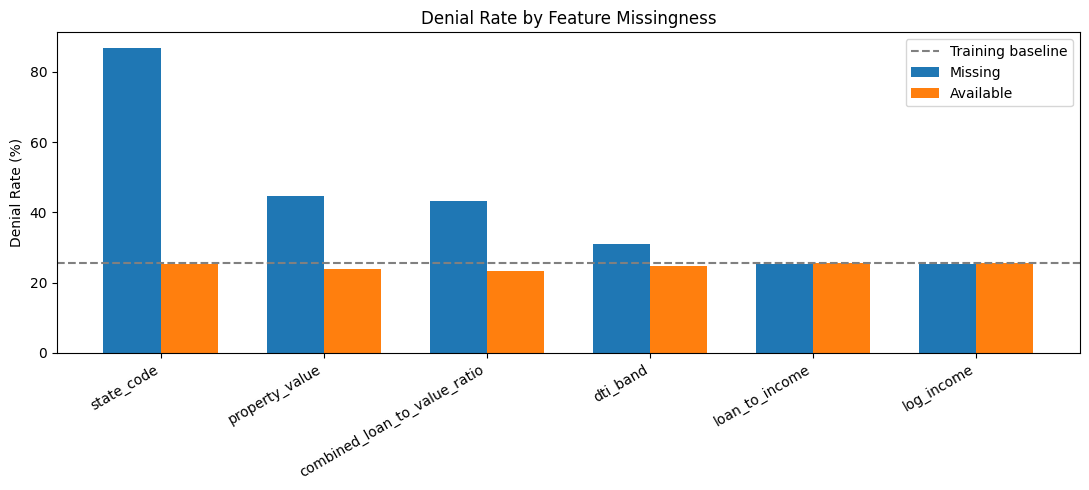

E2 completed successfully.


In [15]:
# ============================================================
# E2. MISSINGNESS AND POTENTIAL LEAKAGE
# ============================================================

# ------------------------------------------------------------
# Step 1. Initialize training data
# ------------------------------------------------------------

import gc

X_train_fe = model_df[FEATURES].iloc[train_idx].reset_index(drop=True)

y_train_fe = (
    model_df[TARGET]
    .iloc[train_idx]
    .reset_index(drop=True)
)

baseline_denial_rate = y_train_fe.mean() * 100

# ------------------------------------------------------------
# Step 2. Analyze missingness by outcome
# ------------------------------------------------------------

missingness_results = []

for col in FEATURES:

    missing_mask = X_train_fe[col].isna()

    n_missing = int(missing_mask.sum())
    n_available = int((~missing_mask).sum())

    if n_missing == 0:
        continue

    missing_denial_rate = (
        y_train_fe[missing_mask].mean() * 100
    )

    available_denial_rate = (
        y_train_fe[~missing_mask].mean() * 100
        if n_available > 0 else np.nan
    )

    missingness_results.append({
        "feature": col,
        "missing_count": n_missing,
        "missing_pct": n_missing / len(X_train_fe) * 100,
        "denial_rate_missing_pct": missing_denial_rate,
        "denial_rate_available_pct": available_denial_rate,
        "denial_rate_gap_pp": (
            missing_denial_rate - available_denial_rate
        )
    })

missingness_df = (
    pd.DataFrame(missingness_results)
    .sort_values("denial_rate_gap_pp", ascending=False)
    .reset_index(drop=True)
)

display(missingness_df.round(4))

print(f"Training denial rate: {baseline_denial_rate:.4f}%")

# ------------------------------------------------------------
# Step 3. Visualize outcome-dependent missingness
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(11, 5))

x = np.arange(len(missingness_df))
width = 0.35

ax.bar(
    x - width / 2,
    missingness_df["denial_rate_missing_pct"],
    width,
    label="Missing"
)

ax.bar(
    x + width / 2,
    missingness_df["denial_rate_available_pct"],
    width,
    label="Available"
)

ax.axhline(
    baseline_denial_rate,
    linestyle="--",
    color="gray",
    label="Training baseline"
)

ax.set_xticks(x)

ax.set_xticklabels(
    missingness_df["feature"],
    rotation=30,
    ha="right"
)

ax.set_ylabel("Denial Rate (%)")
ax.set_title("Denial Rate by Feature Missingness")
ax.legend()

plt.tight_layout()

fig.savefig(
    OUT + "E2_missingness_denial_rate.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 4. Export results
# ------------------------------------------------------------

missingness_df.to_csv(
    OUT + "E2_missingness_analysis.csv",
    index=False
)

print("E2 completed successfully.")

##Numerical Transformation

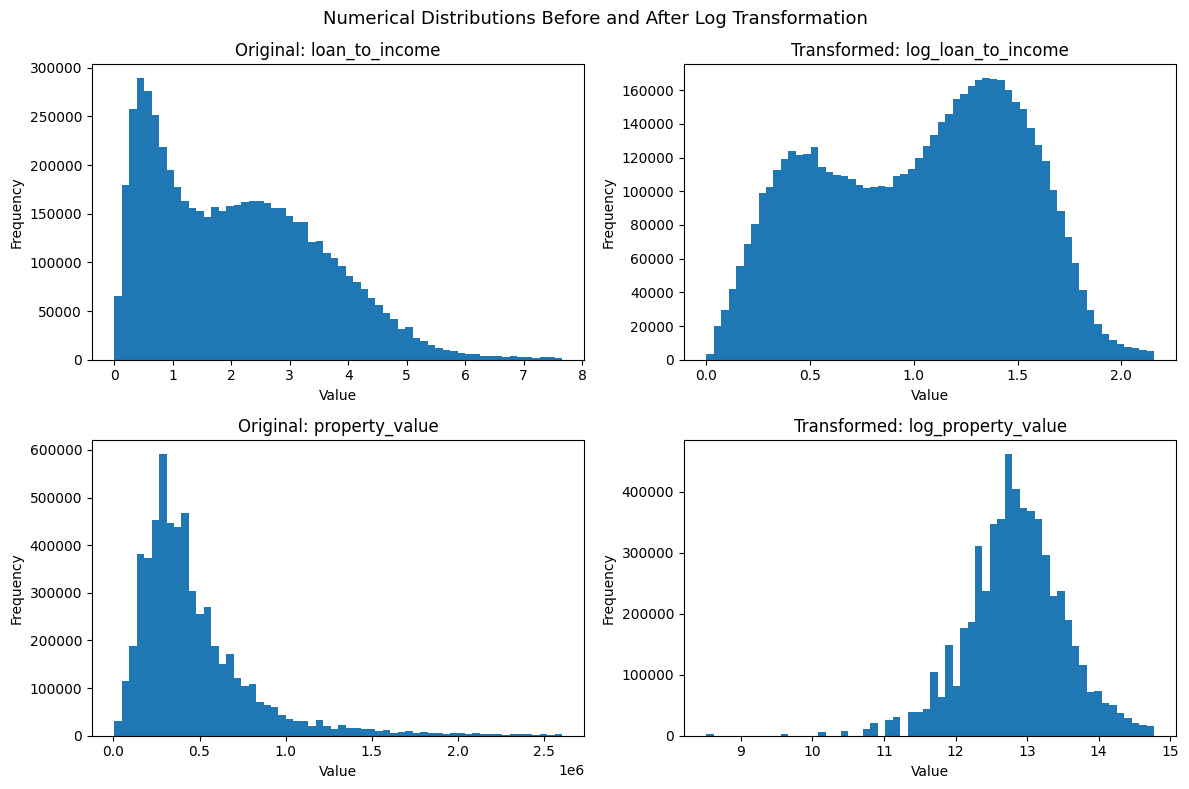

,original_feature,transformed_feature,method,original_skewness,transformed_skewness,original_median,transformed_median,original_max,transformed_max
0,loan_to_income,log_loan_to_income,log1p,127.7901,0.5324,1.9697,1.0885,3.505000e+03,8.1622
1,property_value,log_property_value,log1p,265.3948,0.2226,385000.0000,12.8610,2.147484e+09,21.4876


E3 completed successfully.


In [16]:
# ============================================================
# E3. NUMERICAL TRANSFORMATION
# ============================================================

# ------------------------------------------------------------
# Step 1. Define transformation candidates
# ------------------------------------------------------------

TRANSFORMATION_MAP = {
    "loan_to_income": "log_loan_to_income",
    "property_value": "log_property_value"
}

transformation_results = []

# ------------------------------------------------------------
# Step 2. Compare numerical distributions
# ------------------------------------------------------------

fig, axes = plt.subplots(
    len(TRANSFORMATION_MAP),
    2,
    figsize=(12, 8)
)

for i, (original_col, transformed_col) in enumerate(
    TRANSFORMATION_MAP.items()
):

    original = (
        X_train_fe[original_col]
        .dropna()
        .astype("float64")
    )

    assert (original >= 0).all(), (
        f"Negative values detected in {original_col}"
    )

    transformed = np.log1p(original)

    transformation_results.append({
        "original_feature": original_col,
        "transformed_feature": transformed_col,
        "method": "log1p",
        "original_skewness": original.skew(),
        "transformed_skewness": transformed.skew(),
        "original_median": original.median(),
        "transformed_median": transformed.median(),
        "original_max": original.max(),
        "transformed_max": transformed.max()
    })

    # Limit plotting range for visualization only.

    original_limit = original.quantile(0.99)
    transformed_limit = transformed.quantile(0.99)

    axes[i, 0].hist(
        original[original <= original_limit],
        bins=60
    )

    axes[i, 0].set_title(
        f"Original: {original_col}"
    )

    axes[i, 1].hist(
        transformed[transformed <= transformed_limit],
        bins=60
    )

    axes[i, 1].set_title(
        f"Transformed: {transformed_col}"
    )

    for ax in axes[i]:
        ax.set_ylabel("Frequency")
        ax.set_xlabel("Value")

plt.suptitle(
    "Numerical Distributions Before and After Log Transformation",
    fontsize=13
)

plt.tight_layout()

fig.savefig(
    OUT + "E3_numerical_transformation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 3. Export transformation assessment
# ------------------------------------------------------------

transformation_df = pd.DataFrame(transformation_results)

display(transformation_df.round(4))

transformation_df.to_csv(
    OUT + "E3_transformation_summary.csv",
    index=False
)

print("E3 completed successfully.")

##Correlation and Multicollinearity Assessment

Sample size: 200,000

Pearson Correlation


,log_income,log_loan_amount,combined_loan_to_value_ratio,log_loan_to_income,log_property_value
log_income,1.0000,0.4449,0.0690,-0.3368,0.6080
log_loan_amount,0.4449,1.0000,0.2887,0.6617,0.5217
combined_loan_to_value_ratio,0.0690,0.2887,1.0000,0.2939,-0.2160
log_loan_to_income,-0.3368,0.6617,0.2939,1.0000,0.0655
log_property_value,0.6080,0.5217,-0.2160,0.0655,1.0000



Spearman Correlation


,log_income,log_loan_amount,combined_loan_to_value_ratio,log_loan_to_income,log_property_value
log_income,1.0000,0.4573,0.0097,-0.2788,0.6328
log_loan_amount,0.4573,1.0000,0.3052,0.6768,0.5133
combined_loan_to_value_ratio,0.0097,0.3052,1.0000,0.3363,-0.2475
log_loan_to_income,-0.2788,0.6768,0.3363,1.0000,0.0441
log_property_value,0.6328,0.5133,-0.2475,0.0441,1.0000


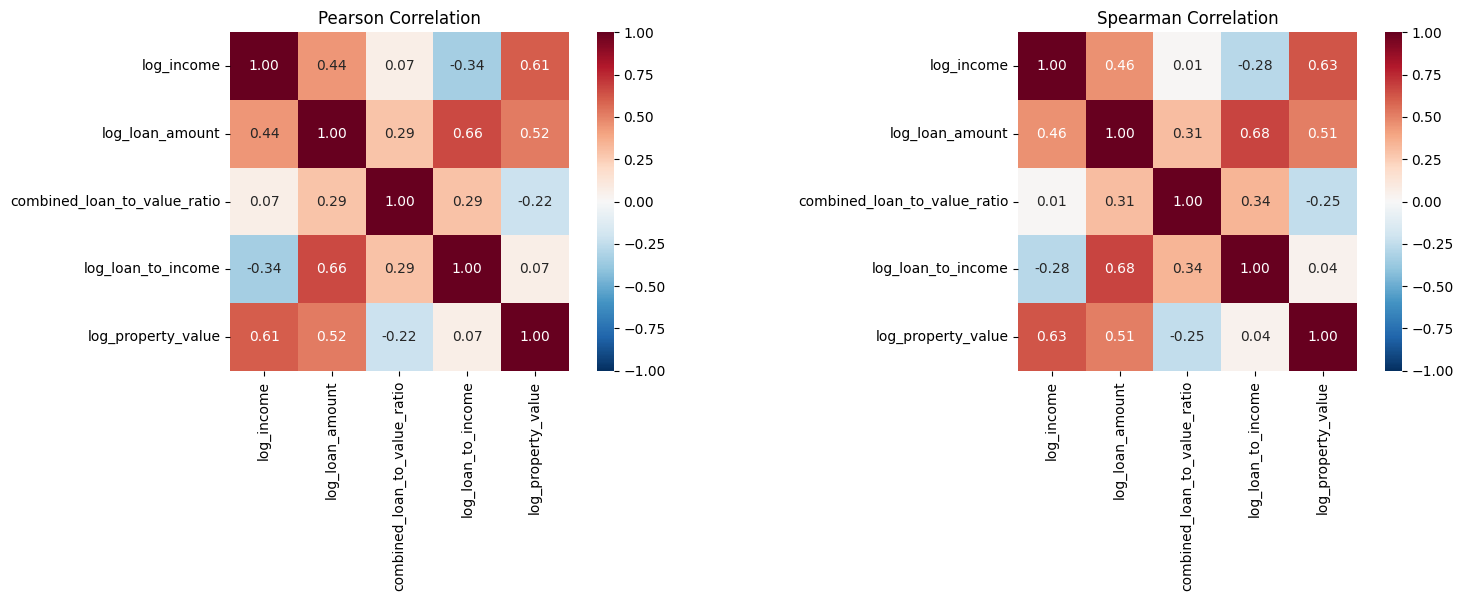


Complete cases for VIF: 165,470


,feature,vif,multicollinearity
0,log_loan_amount,17.7441,High
1,log_loan_to_income,17.5212,High
2,log_income,13.6230,High
3,log_property_value,2.5225,Low
4,combined_loan_to_value_ratio,1.5658,Low


E4 completed successfully.


In [17]:
# ============================================================
# E4. CORRELATION AND MULTICOLLINEARITY
# ============================================================

from statsmodels.stats.outliers_influence import (
    variance_inflation_factor
)

# ------------------------------------------------------------
# Step 1. Prepare transformed numerical sample
# ------------------------------------------------------------

FE_SAMPLE_SIZE = 200_000

numeric_sample = (
    X_train_fe[NUMERIC_FEATURES]
    .sample(
        n=min(FE_SAMPLE_SIZE, len(X_train_fe)),
        random_state=RANDOM_STATE
    )
    .copy()
)

numeric_sample["log_loan_to_income"] = np.log1p(
    numeric_sample.pop("loan_to_income")
)

numeric_sample["log_property_value"] = np.log1p(
    numeric_sample.pop("property_value")
)

numeric_sample = numeric_sample.astype("float64")

print(f"Sample size: {len(numeric_sample):,}")

# ------------------------------------------------------------
# Step 2. Calculate correlations
# ------------------------------------------------------------

pearson_corr = numeric_sample.corr(method="pearson")

spearman_corr = numeric_sample.corr(method="spearman")

print("\nPearson Correlation")

display(pearson_corr.round(4))

print("\nSpearman Correlation")

display(spearman_corr.round(4))

# ------------------------------------------------------------
# Step 3. Visualize correlation matrices
# ------------------------------------------------------------

fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
)

for ax, corr, title in zip(
    axes,
    [pearson_corr, spearman_corr],
    ["Pearson Correlation", "Spearman Correlation"]
):

    sns.heatmap(
        corr,
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        center=0,
        vmin=-1,
        vmax=1,
        square=True,
        ax=ax
    )

    ax.set_title(title)

plt.tight_layout()

fig.savefig(
    OUT + "E4_correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# Step 4. Calculate Variance Inflation Factors
# ------------------------------------------------------------

vif_data = numeric_sample.dropna().copy()

print(f"\nComplete cases for VIF: {len(vif_data):,}")

# Standardize variables before calculating VIF.

vif_scaled = (
    (vif_data - vif_data.mean())
    / vif_data.std(ddof=0)
)

vif_matrix = vif_scaled.to_numpy()

vif_results = []

for i, col in enumerate(vif_scaled.columns):

    vif_value = variance_inflation_factor(
        vif_matrix, i
    )

    if vif_value >= 10:
        assessment = "High"

    elif vif_value >= 5:
        assessment = "Moderate"

    else:
        assessment = "Low"

    vif_results.append({
        "feature": col,
        "vif": vif_value,
        "multicollinearity": assessment
    })

vif_df = (
    pd.DataFrame(vif_results)
    .sort_values("vif", ascending=False)
    .reset_index(drop=True)
)

display(vif_df.round(4))

# ------------------------------------------------------------
# Step 5. Export results
# ------------------------------------------------------------

pearson_corr.to_csv(
    OUT + "E4_pearson_correlation.csv"
)

spearman_corr.to_csv(
    OUT + "E4_spearman_correlation.csv"
)

vif_df.to_csv(
    OUT + "E4_vif_summary.csv",
    index=False
)

del vif_data, vif_scaled, vif_matrix

gc.collect()

print("E4 completed successfully.")

##Final Feature Engineering Configuration

In [18]:
# ============================================================
# E5. FINAL FEATURE ENGINEERING CONFIGURATION
# ============================================================

# ------------------------------------------------------------
# Step 1. Define numerical transformations
# ------------------------------------------------------------

LOG_TRANSFORM_FEATURES = [
    "loan_to_income",
    "property_value"
]

IDENTITY_NUMERIC_FEATURES = [
    col for col in NUMERIC_FEATURES
    if col not in LOG_TRANSFORM_FEATURES
]

# ------------------------------------------------------------
# Step 2. Check redundant missing indicators
# ------------------------------------------------------------

income_lti_same_mask = (
    X_train_fe["log_income"].isna()
    .equals(X_train_fe["loan_to_income"].isna())
)

print(
    "Income and LTI have identical missing masks:",
    income_lti_same_mask
)

MISSING_INDICATOR_FEATURES = [
    "log_income",
    "property_value",
    "combined_loan_to_value_ratio"
]

if not income_lti_same_mask:
    MISSING_INDICATOR_FEATURES.append("loan_to_income")

MISSING_CATEGORY = "Not provided"

# ------------------------------------------------------------
# Step 3. Finalize feature names
# ------------------------------------------------------------

FINAL_NUMERIC_FEATURES = [
    "log_loan_to_income"
    if col == "loan_to_income"
    else "log_property_value"
    if col == "property_value"
    else col
    for col in NUMERIC_FEATURES
]

INDICATOR_NAMES = [
    f"{col}_missing"
    for col in MISSING_INDICATOR_FEATURES
]

FINAL_ENGINEERED_FEATURES = (
    FINAL_NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
    + INDICATOR_NAMES
)

# ------------------------------------------------------------
# Step 4. Save feature engineering configuration
# ------------------------------------------------------------

fe_config = {
    "original_features": FEATURES,
    "original_numeric_features": NUMERIC_FEATURES,
    "categorical_features": CATEGORICAL_FEATURES,
    "log1p_features": LOG_TRANSFORM_FEATURES,
    "identity_numeric_features": IDENTITY_NUMERIC_FEATURES,
    "numeric_imputation": "median",
    "categorical_imputation": "constant",
    "missing_category": MISSING_CATEGORY,
    "missing_indicator_features": MISSING_INDICATOR_FEATURES,
    "missing_indicator_names": INDICATOR_NAMES,
    "final_numeric_features": FINAL_NUMERIC_FEATURES,
    "final_engineered_features": FINAL_ENGINEERED_FEATURES,
    "income_lti_same_missing_mask_train": bool(
        income_lti_same_mask
    )
}

with open(
    OUT + "feature_engineering_config.json",
    "w"
) as f:
    json.dump(fe_config, f, indent=4)

# ------------------------------------------------------------
# Step 5. Display final feature summary
# ------------------------------------------------------------

fe_summary = pd.DataFrame({
    "feature": FINAL_ENGINEERED_FEATURES,
    "feature_type": (
        ["Numeric"] * len(FINAL_NUMERIC_FEATURES)
        + ["Categorical"] * len(CATEGORICAL_FEATURES)
        + ["Missing indicator"] * len(INDICATOR_NAMES)
    )
})

display(fe_summary)

fe_summary.to_csv(
    OUT + "E5_final_feature_summary.csv",
    index=False
)

print(f"Original predictors: {len(FEATURES)}")
print(f"Numerical features: {len(FINAL_NUMERIC_FEATURES)}")
print(f"Categorical features: {len(CATEGORICAL_FEATURES)}")
print(f"Missing indicators: {len(INDICATOR_NAMES)}")

print(
    "Engineered features before encoding:",
    len(FINAL_ENGINEERED_FEATURES)
)

print("E5 completed successfully.")

Income and LTI have identical missing masks: True


,feature,feature_type
0,log_income,Numeric
1,log_loan_amount,Numeric
2,log_loan_to_income,Numeric
3,log_property_value,Numeric
4,combined_loan_to_value_ratio,Numeric
5,loan_type,Categorical
6,loan_purpose,Categorical
7,lien_status,Categorical
8,occupancy_type,Categorical
9,construction_method,Categorical


Original predictors: 12
Numerical features: 5
Categorical features: 7
Missing indicators: 3
Engineered features before encoding: 15
E5 completed successfully.


Based on the training-set analysis, all 12 selected
predictors are retained.

Log transformations are applied to loan-to-income ratio
and property value to reduce skewness and improve
numerical stability.

Missingness is retained as a potential predictive signal
through explicit categorical levels and numerical missing
indicators.

Correlated numerical predictors are retained because
they represent distinct and interpretable financial
dimensions. L2 regularization will be used for Logistic
Regression, while Gradient Boosting is less sensitive
to multicollinearity.

No additional interaction features or redundant
transformations are introduced.

Potential outcome-dependent missingness remains a
methodological limitation of retrospective HMDA modeling.

#Part F. Data Preprocessing

This section establishes a reusable preprocessing framework
for Logistic Regression and Gradient Boosting.

Both models use the same underlying predictors, feature
transformations, categorical encoding, and missingness
handling strategy.

The preprocessing framework includes:

- Log transformations for loan-to-income ratio and property value.
- Median imputation for numerical predictors.
- Binary indicators for numerical missingness.
- Explicit missing categories for categorical predictors.
- One-hot encoding with unknown-category handling.
- Numerical standardization for Logistic Regression only.

Sparse output is used to improve memory efficiency when
processing large-scale HMDA data.

All data-dependent preprocessing parameters are fitted
exclusively on the training subset of each cross-validation
fold.

The held-out test partition remains untouched during
preprocessing development and model selection.

##Build Model-Specific Preprocessing Pipelines

In [19]:
# ============================================================
# F2. BUILD MODEL-SPECIFIC PREPROCESSING PIPELINES
# ============================================================

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    StandardScaler,
    FunctionTransformer
)
from sklearn.impute import SimpleImputer, MissingIndicator
from sklearn.base import clone

from scipy import sparse

# ------------------------------------------------------------
# Step 1. Define numerical preprocessing
# ------------------------------------------------------------

def build_numeric_pipeline(log_transform=False, scale=False):

    steps = []

    if log_transform:
        steps.append(
            (
                "log_transform",
                FunctionTransformer(
                    np.log1p,
                    feature_names_out="one-to-one"
                )
            )
        )

    steps.append(
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    )

    if scale:
        steps.append(
            ("scaler", StandardScaler())
        )

    return Pipeline(steps)

# ------------------------------------------------------------
# Step 2. Define categorical preprocessing
# ------------------------------------------------------------

def build_categorical_pipeline():

    return Pipeline([
        (
            "imputer",
            SimpleImputer(
                strategy="constant",
                fill_value=MISSING_CATEGORY
            )
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=True,
                dtype=np.float32
            )
        )
    ])

# ------------------------------------------------------------
# Step 3. Define missing indicator preprocessing
# ------------------------------------------------------------

def build_missing_indicator():

    return MissingIndicator(
        features="all",
        sparse=True
    )

# ------------------------------------------------------------
# Step 4. Build complete preprocessing pipeline
# ------------------------------------------------------------

def build_preprocessor(scale_numeric=False):

    return ColumnTransformer(
        transformers=[
            (
                "numeric_identity",
                build_numeric_pipeline(
                    log_transform=False,
                    scale=scale_numeric
                ),
                IDENTITY_NUMERIC_FEATURES
            ),
            (
                "numeric_log",
                build_numeric_pipeline(
                    log_transform=True,
                    scale=scale_numeric
                ),
                LOG_TRANSFORM_FEATURES
            ),
            (
                "categorical",
                build_categorical_pipeline(),
                CATEGORICAL_FEATURES
            ),
            (
                "missing_indicator",
                build_missing_indicator(),
                MISSING_INDICATOR_FEATURES
            )
        ],
        remainder="drop",
        sparse_threshold=1.0,
        verbose_feature_names_out=True
    )

# ------------------------------------------------------------
# Step 5. Initialize model-specific preprocessors
# ------------------------------------------------------------

lr_preprocessor = build_preprocessor(
    scale_numeric=True
)

gb_preprocessor = build_preprocessor(
    scale_numeric=False
)

print("Logistic Regression preprocessor: READY")
print("Gradient Boosting preprocessor: READY")

print("\nNumerical identity features:")
print(IDENTITY_NUMERIC_FEATURES)

print("\nNumerical log-transformed features:")
print(LOG_TRANSFORM_FEATURES)

print("\nCategorical features:")
print(CATEGORICAL_FEATURES)

print("\nMissing indicator features:")
print(MISSING_INDICATOR_FEATURES)

print("\nF2 completed successfully.")

Logistic Regression preprocessor: READY
Gradient Boosting preprocessor: READY

Numerical identity features:
['log_income', 'log_loan_amount', 'combined_loan_to_value_ratio']

Numerical log-transformed features:
['loan_to_income', 'property_value']

Categorical features:
['loan_type', 'loan_purpose', 'lien_status', 'occupancy_type', 'construction_method', 'state_code', 'dti_band']

Missing indicator features:
['log_income', 'property_value', 'combined_loan_to_value_ratio']

F2 completed successfully.


##Preprocessing Validation

In [20]:
# ============================================================
# F3. PREPROCESSING VALIDATION
# ============================================================

# ------------------------------------------------------------
# Step 1. Create validation sample
# ------------------------------------------------------------

PREPROCESS_SAMPLE_SIZE = 50_000

preprocess_sample = (
    X_train_fe[FEATURES]
    .sample(
        n=min(
            PREPROCESS_SAMPLE_SIZE,
            len(X_train_fe)
        ),
        random_state=RANDOM_STATE
    )
    .copy()
)

print(f"Validation sample: {len(preprocess_sample):,}")

# ------------------------------------------------------------
# Step 2. Fit temporary preprocessing pipelines
# ------------------------------------------------------------

preprocessors = {
    "Logistic Regression": lr_preprocessor,
    "Gradient Boosting": gb_preprocessor
}

preprocessing_results = []
feature_names_by_model = {}

for model_name, preprocessor in preprocessors.items():

    validation_preprocessor = clone(preprocessor)

    start_time = time.perf_counter()

    transformed = validation_preprocessor.fit_transform(
        preprocess_sample
    )

    elapsed_time = time.perf_counter() - start_time

    feature_names = (
        validation_preprocessor
        .get_feature_names_out()
    )

    feature_names_by_model[model_name] = (
        feature_names.tolist()
    )

    # --------------------------------------------------------
    # Step 3. Inspect transformed output
    # --------------------------------------------------------

    is_sparse = sparse.issparse(transformed)

    if is_sparse:

        values = transformed.data

        memory_mb = (
            transformed.data.nbytes
            + transformed.indices.nbytes
            + transformed.indptr.nbytes
        ) / (1024 ** 2)

        density_pct = (
            transformed.nnz
            / (transformed.shape[0] * transformed.shape[1])
            * 100
        )

    else:

        values = transformed

        memory_mb = transformed.nbytes / (1024 ** 2)

        density_pct = (
            np.count_nonzero(transformed)
            / transformed.size
            * 100
        )

    missing_count = int(np.isnan(values).sum())
    infinity_count = int(np.isinf(values).sum())

    row_check = (
        transformed.shape[0] == len(preprocess_sample)
    )

    feature_check = (
        transformed.shape[1] == len(feature_names)
    )

    preprocessing_results.append({
        "model": model_name,
        "input_rows": len(preprocess_sample),
        "input_features": len(FEATURES),
        "output_rows": transformed.shape[0],
        "output_features": transformed.shape[1],
        "sparse_output": is_sparse,
        "density_pct": density_pct,
        "missing_values": missing_count,
        "infinite_values": infinity_count,
        "memory_mb": memory_mb,
        "processing_time_sec": elapsed_time,
        "row_count_check": row_check,
        "feature_count_check": feature_check
    })

    assert row_check
    assert feature_check
    assert missing_count == 0
    assert infinity_count == 0
    assert is_sparse

    # --------------------------------------------------------
    # Step 4. Verify explicit missing categories
    # --------------------------------------------------------

    missing_category_sample = (
        preprocess_sample.isna().sum()
    )

    for col in CATEGORICAL_FEATURES:

        if missing_category_sample[col] > 0:

            expected_name = (
                f"categorical__{col}_{MISSING_CATEGORY}"
            )

            assert expected_name in feature_names, (
                f"Missing category not encoded: {col}"
            )

    # --------------------------------------------------------
    # Step 5. Validate handling of unseen categories
    # --------------------------------------------------------

    unknown_sample = preprocess_sample.iloc[:1].copy()

    unknown_sample["state_code"] = (
        unknown_sample["state_code"].astype(object)
    )

    unknown_sample.loc[
        :, "state_code"
    ] = "__UNSEEN_STATE__"

    unknown_transformed = (
        validation_preprocessor.transform(
            unknown_sample
        )
    )

    assert unknown_transformed.shape == (
        1,
        transformed.shape[1]
    )

    del transformed
    del validation_preprocessor

    gc.collect()

# ------------------------------------------------------------
# Step 6. Compare model-specific feature spaces
# ------------------------------------------------------------

same_feature_space = (
    feature_names_by_model["Logistic Regression"]
    == feature_names_by_model["Gradient Boosting"]
)

assert same_feature_space

preprocessing_validation_df = pd.DataFrame(
    preprocessing_results
)

display(preprocessing_validation_df.round(4))

print(
    "\nIdentical feature space across models:",
    same_feature_space
)

print("Unknown category handling: PASS")

print("All preprocessing validation checks: PASS")

# ------------------------------------------------------------
# Step 7. Export validation results
# ------------------------------------------------------------

preprocessing_validation_df.to_csv(
    OUT + "F3_preprocessing_validation.csv",
    index=False
)

sample_feature_names_df = pd.DataFrame({
    "feature": feature_names_by_model[
        "Logistic Regression"
    ]
})

sample_feature_names_df.to_csv(
    OUT + "F3_sample_encoded_features.csv",
    index=False
)

print("\nF3 completed successfully.")

Validation sample: 50,000


,model,input_rows,input_features,output_rows,output_features,sparse_output,density_pct,missing_values,infinite_values,memory_mb,processing_time_sec,row_count_check,feature_count_check
0,Logistic Regression,50000,12,50000,86,True,14.2557,0,0,4.8675,0.1046,True,True
1,Gradient Boosting,50000,12,50000,86,True,14.2552,0,0,4.8674,0.0974,True,True



Identical feature space across models: True
Unknown category handling: PASS
All preprocessing validation checks: PASS

F3 completed successfully.


##Export Reusable Preprocessing Artifacts

In [21]:
# ============================================================
# F4. EXPORT REUSABLE PREPROCESSING ARTIFACTS
# ============================================================

# ------------------------------------------------------------
# Step 1. Export unfitted preprocessing pipelines
# ------------------------------------------------------------

joblib.dump(
    lr_preprocessor,
    OUT + "lr_preprocessor.joblib"
)

joblib.dump(
    gb_preprocessor,
    OUT + "gb_preprocessor.joblib"
)

# ------------------------------------------------------------
# Step 2. Define preprocessing configuration
# ------------------------------------------------------------

preprocessing_config = {
    "original_features": FEATURES,

    "identity_numeric_features": (
        IDENTITY_NUMERIC_FEATURES
    ),

    "log1p_features": LOG_TRANSFORM_FEATURES,

    "categorical_features": CATEGORICAL_FEATURES,

    "missing_indicator_features": (
        MISSING_INDICATOR_FEATURES
    ),

    "numeric_imputation": "median",

    "categorical_imputation": "constant",

    "missing_category": MISSING_CATEGORY,

    "categorical_encoding": "one-hot",

    "unknown_category_handling": "ignore",

    "logistic_regression_scaling": "StandardScaler",

    "gradient_boosting_scaling": None,

    "sparse_output": True,

    "fit_scope": "Training subset of each CV fold",

    "preprocessor_status": "unfitted"
}

with open(
    OUT + "preprocessing_config.json",
    "w"
) as f:

    json.dump(
        preprocessing_config,
        f,
        indent=4
    )

# ------------------------------------------------------------
# Step 3. Verify saved artifacts
# ------------------------------------------------------------

preprocessing_artifacts = [
    "lr_preprocessor.joblib",
    "gb_preprocessor.joblib",
    "preprocessing_config.json"
]

artifact_results = []

for filename in preprocessing_artifacts:

    path = OUT + filename

    exists = os.path.exists(path)

    assert exists

    artifact_results.append({
        "artifact": filename,
        "size_kb": os.path.getsize(path) / 1024,
        "status": "PASS"
    })

display(
    pd.DataFrame(artifact_results).round(4)
)

# ------------------------------------------------------------
# Step 4. Release temporary data
# ------------------------------------------------------------

del preprocess_sample

gc.collect()

print("\nF4 completed successfully.")
print("All preprocessing artifacts exported.")

,artifact,size_kb,status
0,lr_preprocessor.joblib,1.6572,PASS
1,gb_preprocessor.joblib,1.5322,PASS
2,preprocessing_config.json,1.2676,PASS



F4 completed successfully.
All preprocessing artifacts exported.


#Part G. Class Imbalance Handling Strategy

The training population exhibits moderate class imbalance,
with 74.48% originated applications and 25.52% denied
applications, corresponding to an imbalance ratio of
approximately 2.92:1.

Given the substantial number of minority-class observations,
resampling techniques are not prioritized.

Both Logistic Regression and Gradient Boosting will evaluate
two class imbalance strategies:

- Unweighted training as the baseline.
- Balanced class weighting as an alternative configuration.

Class weights will be calculated independently within each
cross-validation training fold.

Validation and test sets will retain their original class
distributions to ensure realistic performance evaluation.

The final imbalance handling strategy will be selected
during model training and hyperparameter tuning.

No resampling or class weighting is applied during the
model setup stage.

#Part H. Evaluation Framework

## Evaluation Strategy

A consistent evaluation framework is established for
Logistic Regression and Gradient Boosting to ensure
a fair and reproducible comparison.

Average Precision (AP), representing the area under
the precision-recall curve using the average precision
definition, is selected as the primary model selection metric.

Secondary and supporting metrics include:

- ROC-AUC
- Precision
- Recall
- F1-score
- Accuracy
- Specificity
- Brier Score
- Confusion Matrix
- Training Time
- Inference Time

Model configurations are selected using mean Average
Precision across the five lender-grouped CV folds.

Both mean and standard deviation of cross-validation
performance are reported.

Classification performance is evaluated at two thresholds:

- Default probability threshold of 0.5.
- Optimized threshold maximizing F1-score on pooled
  out-of-fold predictions from the selected configuration.

The held-out test partition is used only for final
evaluation after model configuration and classification
threshold selection are completed.

Both models are evaluated on identical test applications
and previously unseen lenders.

##Define Reusable Evaluation Functions

In [22]:
# ============================================================
# H2. DEFINE REUSABLE EVALUATION FUNCTIONS
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# Step 1. Define shared evaluation module
# ------------------------------------------------------------

evaluation_module = '''
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    precision_recall_curve,
    brier_score_loss
)


# ------------------------------------------------------------
# Function 1. Evaluate probability-based predictions
# ------------------------------------------------------------

def evaluate_predictions(y_true, y_prob, threshold=0.5):

    y_true = np.asarray(y_true)
    y_prob = np.asarray(y_prob)

    y_pred = (y_prob >= threshold).astype(np.int8)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    specificity = (
        tn / (tn + fp)
        if (tn + fp) > 0
        else 0.0
    )

    return {
        "threshold": float(threshold),

        "average_precision": average_precision_score(
            y_true, y_prob
        ),

        "roc_auc": roc_auc_score(
            y_true, y_prob
        ),

        "accuracy": accuracy_score(
            y_true, y_pred
        ),

        "precision": precision_score(
            y_true, y_pred, zero_division=0
        ),

        "recall": recall_score(
            y_true, y_pred, zero_division=0
        ),

        "f1": f1_score(
            y_true, y_pred, zero_division=0
        ),

        "specificity": specificity,

        "brier_score": brier_score_loss(
            y_true, y_prob
        ),

        "true_negative": int(tn),
        "false_positive": int(fp),
        "false_negative": int(fn),
        "true_positive": int(tp)
    }


# ------------------------------------------------------------
# Function 2. Optimize classification threshold
# ------------------------------------------------------------

def optimize_f1_threshold(y_true, y_prob):

    precision, recall, thresholds = precision_recall_curve(
        y_true, y_prob
    )

    precision = precision[:-1]
    recall = recall[:-1]

    denominator = precision + recall

    f1_values = np.divide(
        2 * precision * recall,
        denominator,
        out=np.zeros_like(denominator),
        where=denominator > 0
    )

    best_idx = np.argmax(f1_values)

    return {
        "optimal_threshold": float(thresholds[best_idx]),
        "optimal_f1": float(f1_values[best_idx]),
        "precision": float(precision[best_idx]),
        "recall": float(recall[best_idx])
    }


# ------------------------------------------------------------
# Function 3. Summarize cross-validation performance
# ------------------------------------------------------------

def summarize_cv_results(cv_results):

    results_df = pd.DataFrame(cv_results)

    metric_columns = [
        "average_precision",
        "roc_auc",
        "accuracy",
        "precision",
        "recall",
        "f1",
        "specificity",
        "brier_score",
        "training_time_sec",
        "inference_time_sec"
    ]

    available_metrics = [
        col for col in metric_columns
        if col in results_df.columns
    ]

    summary = (
        results_df[available_metrics]
        .agg(["mean", "std"])
        .T
        .reset_index()
        .rename(columns={"index": "metric"})
    )

    return summary


# ------------------------------------------------------------
# Function 4. Calculate balanced class weights
# ------------------------------------------------------------

def calculate_class_weights(y_train):

    y_train = np.asarray(y_train)

    classes, counts = np.unique(
        y_train,
        return_counts=True
    )

    n_samples = len(y_train)
    n_classes = len(classes)

    return {
        int(cls): float(
            n_samples / (n_classes * count)
        )
        for cls, count in zip(classes, counts)
    }


# ------------------------------------------------------------
# Function 5. Generate balanced sample weights
# ------------------------------------------------------------

def calculate_sample_weights(y_train):

    y_train = np.asarray(y_train)

    class_weights = calculate_class_weights(y_train)

    return np.asarray(
        [class_weights[int(label)] for label in y_train],
        dtype=np.float32
    )
'''

# ------------------------------------------------------------
# Step 2. Export shared evaluation module
# ------------------------------------------------------------

evaluation_path = Path(OUT) / "evaluation_utils.py"

evaluation_path.write_text(
    evaluation_module,
    encoding="utf-8"
)

print("Evaluation module exported successfully.")

print(evaluation_path)

Evaluation module exported successfully.
/content/drive/MyDrive/hmda/rq4_setup/evaluation_utils.py


##Validate Function

In [23]:
# ============================================================
# H3. VALIDATE EVALUATION FUNCTIONS
# ============================================================

import importlib.util

# ------------------------------------------------------------
# Step 1. Import shared evaluation module
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "evaluation_utils",
    evaluation_path
)

evaluation_utils = importlib.util.module_from_spec(spec)

spec.loader.exec_module(evaluation_utils)

# ------------------------------------------------------------
# Step 2. Create synthetic validation data
# ------------------------------------------------------------

y_demo = np.array([
    0, 0, 0, 0, 0, 0, 0, 1, 1, 1
])

prob_demo = np.array([
    0.05, 0.10, 0.15, 0.20, 0.25,
    0.30, 0.60, 0.40, 0.70, 0.90
])

# ------------------------------------------------------------
# Step 3. Validate evaluation metrics
# ------------------------------------------------------------

demo_metrics = evaluation_utils.evaluate_predictions(
    y_demo,
    prob_demo,
    threshold=0.5
)

assert np.isclose(
    demo_metrics["accuracy"], 0.8
)

assert np.isclose(
    demo_metrics["specificity"], 6 / 7
)

assert np.isclose(
    demo_metrics["recall"], 2 / 3
)

assert demo_metrics["true_positive"] == 2
assert demo_metrics["true_negative"] == 6
assert demo_metrics["false_positive"] == 1
assert demo_metrics["false_negative"] == 1

# ------------------------------------------------------------
# Step 4. Validate threshold optimization
# ------------------------------------------------------------

demo_threshold = evaluation_utils.optimize_f1_threshold(
    y_demo,
    prob_demo
)

optimized_metrics = (
    evaluation_utils.evaluate_predictions(
        y_demo,
        prob_demo,
        threshold=demo_threshold["optimal_threshold"]
    )
)

assert np.isclose(
    optimized_metrics["f1"],
    demo_threshold["optimal_f1"]
)

assert (
    optimized_metrics["f1"]
    >= demo_metrics["f1"]
)

# ------------------------------------------------------------
# Step 5. Validate class weighting functions
# ------------------------------------------------------------

demo_class_weights = (
    evaluation_utils.calculate_class_weights(y_demo)
)

demo_sample_weights = (
    evaluation_utils.calculate_sample_weights(y_demo)
)

assert len(demo_sample_weights) == len(y_demo)

assert np.isclose(
    demo_sample_weights[y_demo == 0].sum(),
    demo_sample_weights[y_demo == 1].sum()
)

# ------------------------------------------------------------
# Step 6. Validate CV summary function
# ------------------------------------------------------------

demo_cv_summary = (
    evaluation_utils.summarize_cv_results(
        [demo_metrics, optimized_metrics]
    )
)

assert not demo_cv_summary.empty

# ------------------------------------------------------------
# Step 7. Display validation results
# ------------------------------------------------------------

evaluation_checks = pd.DataFrame({
    "validation_check": [
        "Classification metrics",
        "Confusion matrix",
        "Threshold optimization",
        "Balanced class weights",
        "Balanced sample weights",
        "CV summary function"
    ],
    "status": ["PASS"] * 6
})

display(evaluation_checks)

evaluation_checks.to_csv(
    OUT + "H3_evaluation_validation.csv",
    index=False
)

print("All evaluation function checks: PASS")

,validation_check,status
0,Classification metrics,PASS
1,Confusion matrix,PASS
2,Threshold optimization,PASS
3,Balanced class weights,PASS
4,Balanced sample weights,PASS
5,CV summary function,PASS


All evaluation function checks: PASS


##Save Configuration

In [24]:
# ============================================================
# H4. SAVE EVALUATION CONFIGURATION
# ============================================================

evaluation_config = {
    "positive_class": 1,
    "positive_class_label": "Denied",
    "negative_class": 0,
    "negative_class_label": "Originated",

    "primary_metric": "roc_auc",

    "secondary_metrics": [
        "precision"
    ],

    "supporting_metrics": [
        "average_precision",
        "recall",
        "f1",
        "accuracy",
        "specificity",
        "brier_score",
        "confusion_matrix",
        "training_time_sec",
        "inference_time_sec"
    ],

    "model_selection": {
        "method": "Maximum mean CV ROC-AUC",
        "cv_method": "GroupKFold",
        "n_splits": N_SPLITS,
        "group_column": GROUP
    },

    "threshold_selection": {
        "default_threshold": 0.5,
        "optimization_metric": "f1",
        "optimization_data": "Out-of-fold predictions"
    },

    "class_imbalance": {
        "strategies": [
            "unweighted",
            "balanced"
        ],
        "resampling": False,
        "weight_fit_scope": "CV training fold"
    },

    "test_policy": {
        "held_out": True,
        "threshold_tuning_allowed": False,
        "hyperparameter_tuning_allowed": False
    }
}

with open(
    OUT + "evaluation_config.json",
    "w"
) as f:

    json.dump(
        evaluation_config,
        f,
        indent=4
    )

print("Evaluation configuration exported successfully.")

print("Primary metric: ROC-AUC")
print("Secondary metric: Precision")
print("Threshold optimization: F1-score")
print("Cross-validation: Lender-grouped 5-fold CV")

print("\nPart H completed successfully.")

Evaluation configuration exported successfully.
Primary metric: ROC-AUC
Secondary metric: Precision
Threshold optimization: F1-score
Cross-validation: Lender-grouped 5-fold CV

Part H completed successfully.


# Part I. Shared Modeling Artifacts

This section consolidates the artifacts generated
throughout the model setup stage.

The shared artifacts ensure that Logistic Regression
and Gradient Boosting use consistent:

- Modeling populations and target definitions.
- Original predictors and feature engineering rules.
- Lender-grouped training and test partitions.
- Cross-validation fold assignments.
- Model-specific preprocessing pipelines.
- Class imbalance handling strategies.
- Evaluation metrics and threshold selection procedures.

Preprocessing pipelines remain unfitted until the
model training stage.

Model-specific hyperparameter tuning and training
are conducted independently using the shared framework.

Lender-level assignments serve as the authoritative
source for reconstructing train/test and CV partitions.

##Master Configuraion

In [25]:
# ============================================================
# I2. CREATE MASTER MODELING CONFIGURATION
# ============================================================

import sklearn
import scipy
import pyarrow

# ------------------------------------------------------------
# Step 1. Load existing configurations
# ------------------------------------------------------------

config_files = {
    "feature_selection": "feature_config.json",
    "train_test_split": "split_config.json",
    "cross_validation": "cv_config.json",
    "feature_engineering": "feature_engineering_config.json",
    "preprocessing": "preprocessing_config.json",
    "evaluation": "evaluation_config.json"
}

shared_configs = {}

for config_name, filename in config_files.items():

    config_path = os.path.join(OUT, filename)

    assert os.path.exists(config_path), (
        f"Missing configuration: {filename}"
    )

    with open(config_path, "r") as f:

        shared_configs[config_name] = json.load(f)

# ------------------------------------------------------------
# Step 2. Define software environment
# ------------------------------------------------------------

software_versions = {
    "python": sys.version.split()[0],
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "scipy": scipy.__version__,
    "scikit_learn": sklearn.__version__,
    "pyarrow": pyarrow.__version__,
    "joblib": joblib.__version__
}

# ------------------------------------------------------------
# Step 3. Build master configuration
# ------------------------------------------------------------

master_config = {

    "project": "HMDA 2024 - Big Data Group 6",

    "research_question": "RQ4 - Loan Denial Prediction",

    "setup_version": "1.0.0",

    "data_path": DATA_PATH,

    "output_directory": OUT,

    "random_state": RANDOM_STATE,

    "population": {
        "total_applications": len(model_df),
        "training_applications": len(train_idx),
        "test_applications": len(test_idx),
        "total_lenders": int(model_df[GROUP].nunique()),
        "training_lenders": len(train_lenders),
        "test_lenders": len(test_lenders)
    },

    "models": [
        "Logistic Regression",
        "Gradient Boosting"
    ],

    "configurations": shared_configs,

    "shared_artifacts": {
        "lender_split": "lender_train_test_split.csv",
        "cv_fold_assignment": "lender_cv_fold_assignment.csv",
        "train_test_indices": "train_test_indices.npz",
        "cv_fold_array": "cv_fold_assignment.npy",
        "lr_preprocessor": "lr_preprocessor.joblib",
        "gb_preprocessor": "gb_preprocessor.joblib",
        "evaluation_module": "evaluation_utils.py"
    },

    "software_versions": software_versions
}

# ------------------------------------------------------------
# Step 4. Export master configuration
# ------------------------------------------------------------

with open(
    OUT + "master_modeling_config.json",
    "w"
) as f:

    json.dump(
        master_config,
        f,
        indent=4
    )

display(
    pd.DataFrame(
        software_versions.items(),
        columns=["library", "version"]
    )
)

print("Master modeling configuration exported.")

,library,version
0,python,3.13.18
1,numpy,2.4.6
2,pandas,2.2.3
3,scipy,1.16.3
4,scikit_learn,1.6.1
5,pyarrow,23.0.1
6,joblib,1.6.0


Master modeling configuration exported.


##Final Artifact Integrity Check

In [26]:
# ============================================================
# I3. FINAL ARTIFACT INTEGRITY CHECK
# ============================================================

# ------------------------------------------------------------
# Step 1. Define required shared artifacts
# ------------------------------------------------------------

REQUIRED_ARTIFACTS = {
    "feature_config.json": "Feature selection",
    "split_config.json": "Train/test strategy",
    "cv_config.json": "Cross-validation strategy",

    "lender_train_test_split.csv": "Lender partition",
    "train_test_indices.npz": "Partition indices",

    "lender_cv_fold_assignment.csv": "CV lender mapping",
    "cv_fold_assignment.npy": "CV fold array",

    "feature_engineering_config.json": "Feature engineering",

    "lr_preprocessor.joblib": "LR preprocessing",
    "gb_preprocessor.joblib": "GB preprocessing",

    "preprocessing_config.json": "Preprocessing strategy",

    "evaluation_utils.py": "Evaluation functions",
    "evaluation_config.json": "Evaluation strategy",

    "master_modeling_config.json": "Master configuration"
}

# ------------------------------------------------------------
# Step 2. Verify required files
# ------------------------------------------------------------

artifact_results = []

for filename, purpose in REQUIRED_ARTIFACTS.items():

    filepath = os.path.join(OUT, filename)

    exists = os.path.isfile(filepath)

    size_bytes = (
        os.path.getsize(filepath)
        if exists
        else 0
    )

    artifact_results.append({
        "artifact": filename,
        "purpose": purpose,
        "size_mb": size_bytes / (1024 ** 2),
        "status": (
            "PASS"
            if exists and size_bytes > 0
            else "FAIL"
        )
    })

artifact_manifest = pd.DataFrame(
    artifact_results
)

display(artifact_manifest.round(4))

assert (
    artifact_manifest["status"] == "PASS"
).all(), "One or more shared artifacts are missing."

# ------------------------------------------------------------
# Step 3. Reload lender assignments
# ------------------------------------------------------------

saved_lender_split = pd.read_csv(
    OUT + "lender_train_test_split.csv",
    dtype={GROUP: str}
)

saved_cv_split = pd.read_csv(
    OUT + "lender_cv_fold_assignment.csv",
    dtype={GROUP: str}
)

saved_train_lenders = set(
    saved_lender_split.loc[
        saved_lender_split["partition"] == "train",
        GROUP
    ]
)

saved_test_lenders = set(
    saved_lender_split.loc[
        saved_lender_split["partition"] == "test",
        GROUP
    ]
)

saved_cv_lenders = set(
    saved_cv_split[GROUP]
)

# ------------------------------------------------------------
# Step 4. Validate lender assignment consistency
# ------------------------------------------------------------

assert saved_lender_split[GROUP].is_unique
assert saved_cv_split[GROUP].is_unique

assert saved_train_lenders == train_lenders
assert saved_test_lenders == test_lenders

assert not saved_train_lenders.intersection(
    saved_test_lenders
)

assert saved_cv_lenders == saved_train_lenders

assert not saved_cv_lenders.intersection(
    saved_test_lenders
)

assert set(
    saved_cv_split["validation_fold"]
) == set(range(1, N_SPLITS + 1))

# ------------------------------------------------------------
# Step 5. Validate saved preprocessors
# ------------------------------------------------------------

from sklearn.exceptions import NotFittedError
from sklearn.utils.validation import check_is_fitted

for filename in [
    "lr_preprocessor.joblib",
    "gb_preprocessor.joblib"
]:

    saved_preprocessor = joblib.load(
        OUT + filename
    )

    try:

        check_is_fitted(saved_preprocessor)

        raise AssertionError(
            f"{filename} should remain unfitted."
        )

    except NotFittedError:

        print(f"{filename}: Unfitted status PASS")

    del saved_preprocessor

# ------------------------------------------------------------
# Step 6. Export artifact manifest
# ------------------------------------------------------------

artifact_manifest.to_csv(
    OUT + "modeling_artifact_manifest.csv",
    index=False
)

# ------------------------------------------------------------
# Step 7. Display final validation status
# ------------------------------------------------------------

final_validation = pd.DataFrame({
    "validation_check": [
        "Required artifacts exist",
        "Unique lender assignments",
        "Train/test lender consistency",
        "Zero train/test lender overlap",
        "Complete CV lender coverage",
        "No test lenders in CV",
        "Complete CV fold assignments",
        "Preprocessing pipelines remain unfitted"
    ],
    "status": ["PASS"] * 8
})

display(final_validation)

final_validation.to_csv(
    OUT + "I3_final_setup_validation.csv",
    index=False
)

print("All shared artifact integrity checks: PASS")

,artifact,purpose,size_mb,status
0,feature_config.json,Feature selection,0.0010,PASS
1,split_config.json,Train/test strategy,0.0003,PASS
2,cv_config.json,Cross-validation strategy,0.0003,PASS
3,lender_train_test_split.csv,Lender partition,0.1255,PASS
4,train_test_indices.npz,Partition indices,11.9970,PASS
5,lender_cv_fold_assignment.csv,CV lender mapping,0.0862,PASS
6,cv_fold_assignment.npy,CV fold array,6.0162,PASS
7,feature_engineering_config.json,Feature engineering,0.0019,PASS
8,lr_preprocessor.joblib,LR preprocessing,0.0016,PASS
9,gb_preprocessor.joblib,GB preprocessing,0.0015,PASS


lr_preprocessor.joblib: Unfitted status PASS
gb_preprocessor.joblib: Unfitted status PASS


,validation_check,status
0,Required artifacts exist,PASS
1,Unique lender assignments,PASS
2,Train/test lender consistency,PASS
3,Zero train/test lender overlap,PASS
4,Complete CV lender coverage,PASS
5,No test lenders in CV,PASS
6,Complete CV fold assignments,PASS
7,Preprocessing pipelines remain unfitted,PASS


All shared artifact integrity checks: PASS


#Set Up Summary

In [27]:
# ============================================================
# I4. FINAL MODEL SETUP SUMMARY
# ============================================================

# ------------------------------------------------------------
# Step 1. Build setup summary
# ------------------------------------------------------------

setup_summary = pd.DataFrame([
    ["Total applications", f"{len(model_df):,}"],

    ["Training applications", f"{len(train_idx):,}"],

    ["Test applications", f"{len(test_idx):,}"],

    ["Total lenders", f"{model_df[GROUP].nunique():,}"],

    ["Training lenders", f"{len(train_lenders):,}"],

    ["Test lenders", f"{len(test_lenders):,}"],

    ["Target variable", TARGET],

    ["Positive class", "Denied"],

    ["Original predictors", len(FEATURES)],

    ["Numerical predictors", len(NUMERIC_FEATURES)],

    ["Categorical predictors", len(CATEGORICAL_FEATURES)],

    ["Missing indicators", len(MISSING_INDICATOR_FEATURES)],

    ["Engineered features before encoding",
     len(FINAL_ENGINEERED_FEATURES)],

    ["Additional log transformations",
     len(LOG_TRANSFORM_FEATURES)],

    ["Train/test method", "GroupShuffleSplit"],

    ["Cross-validation method", "GroupKFold"],

    ["CV folds", N_SPLITS],

    ["Grouping variable", GROUP],

    ["Class imbalance strategy",
     "Unweighted vs. balanced"],

    ["Primary evaluation metric", "ROC-AUC"],

    ["Secondary evaluation metric", "Precision"],

    ["Threshold optimization", "F1-score"],

    ["Models", "Logistic Regression and Gradient Boosting"],

    ["Setup version", "1.0.0"],

    ["Setup status", "COMPLETE"]

], columns=["component", "configuration"])

display(setup_summary)

# ------------------------------------------------------------
# Step 2. Export final setup summary
# ------------------------------------------------------------

setup_summary.to_csv(
    OUT + "model_setup_summary.csv",
    index=False
)

# ------------------------------------------------------------
# Step 3. Final completion message
# ------------------------------------------------------------

print("=" * 60)
print("STEP 15 - MODEL SETUP COMPLETED")
print("=" * 60)

print(f"Shared artifact directory: {OUT}")

print("\nNext steps:")

print("- Logistic Regression Training and Tuning")
print("- Gradient Boosting Training and Tuning")
print("- Final Model Evaluation")

print("=" * 60)

,component,configuration
0,Total applications,"8,300,547"
1,Training applications,"6,308,273"
2,Test applications,"1,992,274"
3,Total lenders,"4,909"
4,Training lenders,"3,927"
5,Test lenders,982
6,Target variable,denied_flag
7,Positive class,Denied
8,Original predictors,12
9,Numerical predictors,5


STEP 15 - MODEL SETUP COMPLETED
Shared artifact directory: /content/drive/MyDrive/hmda/rq4_setup/

Next steps:
- Logistic Regression Training and Tuning
- Gradient Boosting Training and Tuning
- Final Model Evaluation
